# 📌 Feature Engineering: Working with Dates & Time


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datetime

# 1) Load Datasets


In [3]:
orders_df = pd.read_csv('orders.csv')       # date + product/city/orders
messages_df = pd.read_csv('messages.csv')   # datetime + msg

print("✅ Orders Data Sample:")
print(orders_df.head(), "\n")

print("✅ Messages Data Sample:")
print(messages_df.head(), "\n")


✅ Orders Data Sample:
         date  product_id  city_id  orders
0  2019-12-10        5628       25       3
1  2018-08-15        3646       14     157
2  2018-10-23        1859       25       1
3  2019-08-17        7292       25       1
4  2019-01-06        4344       25       3 

✅ Messages Data Sample:
                  date                                                msg
0  2013-12-15 00:50:00                           ищу на сегодня мужика 37
1  2014-04-29 23:40:00   ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826
2  2012-12-30 00:21:00           Днепр.м 43 позн.с д/ж *.о  067.16.34.576
3  2014-11-28 00:31:00  КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...
4  2013-10-26 23:11:00    Зая я тебя никогда не обижу  люблю тебя!)  Даше 



# 2) Check Data Types (Before Conversion)


In [4]:

print("✅ Orders Info (Before datetime):")
print(orders_df.info(), "\n")

print("✅ Messages Info (Before datetime):")
print(messages_df.info(), "\n")

✅ Orders Info (Before datetime):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        1000 non-null   object
 1   product_id  1000 non-null   int64 
 2   city_id     1000 non-null   int64 
 3   orders      1000 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 31.4+ KB
None 

✅ Messages Info (Before datetime):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   date    1000 non-null   object
 1   msg     1000 non-null   object
dtypes: object(2)
memory usage: 15.8+ KB
None 



# 3) Convert 'date' Columns to Datetime


In [5]:
# orders_df has only date (YYYY-MM-DD)
orders_df['date'] = pd.to_datetime(orders_df['date'])

# messages_df has date + time (YYYY-MM-DD HH:MM:SS)
messages_df['date'] = pd.to_datetime(messages_df['date'])

print("✅ Orders Info (After datetime):")
print(orders_df.info(), "\n")

print("✅ Messages Info (After datetime):")
print(messages_df.info(), "\n")

✅ Orders Info (After datetime):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        1000 non-null   datetime64[ns]
 1   product_id  1000 non-null   int64         
 2   city_id     1000 non-null   int64         
 3   orders      1000 non-null   int64         
dtypes: datetime64[ns](1), int64(3)
memory usage: 31.4 KB
None 

✅ Messages Info (After datetime):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    1000 non-null   datetime64[ns]
 1   msg     1000 non-null   object        
dtypes: datetime64[ns](1), object(1)
memory usage: 15.8+ KB
None 



# 4) Date Feature Extraction (Orders Dataset)


In [6]:
# Year
orders_df['date_year'] = orders_df['date'].dt.year

# Month Number (1-12)
orders_df['date_month_no'] = orders_df['date'].dt.month

# Month Name (January, February...)
orders_df['date_month_name'] = orders_df['date'].dt.month_name()

# Day of Month (1-31)
orders_df['date_day'] = orders_df['date'].dt.day

# Day of Week (0=Monday ... 6=Sunday)
orders_df['date_dow'] = orders_df['date'].dt.dayofweek

# Day Name (Monday, Tuesday...)
orders_df['date_dow_name'] = orders_df['date'].dt.day_name()

# Is Weekend? (Saturday/Sunday => 1 else 0)
orders_df['date_is_weekend'] = np.where(
    orders_df['date_dow_name'].isin(['Saturday', 'Sunday']),
    1, 0
)

# Week of Year (recommended method)
orders_df['date_week'] = orders_df['date'].dt.isocalendar().week.astype(int)

# Quarter (1-4)
orders_df['quarter'] = orders_df['date'].dt.quarter

# Semester (1 => Q1,Q2 | 2 => Q3,Q4)
orders_df['semester'] = np.where(orders_df['quarter'].isin([1, 2]), 1, 2)

print("✅ Orders Dataset after Date Feature Engineering:")
print(orders_df.head(), "\n")

✅ Orders Dataset after Date Feature Engineering:
        date  product_id  city_id  orders  date_year  date_month_no  \
0 2019-12-10        5628       25       3       2019             12   
1 2018-08-15        3646       14     157       2018              8   
2 2018-10-23        1859       25       1       2018             10   
3 2019-08-17        7292       25       1       2019              8   
4 2019-01-06        4344       25       3       2019              1   

  date_month_name  date_day  date_dow date_dow_name  date_is_weekend  \
0        December        10         1       Tuesday                0   
1          August        15         2     Wednesday                0   
2         October        23         1       Tuesday                0   
3          August        17         5      Saturday                1   
4         January         6         6        Sunday                1   

   date_week  quarter  semester  
0         50        4         2  
1         33        3  

# 5) Time Elapsed Features (Orders Dataset)


In [7]:
today = datetime.datetime.today()
print("✅ Today's DateTime:", today, "\n")

# Days difference
orders_df['days_passed'] = (today - orders_df['date']).dt.days

# Months difference (better approx: year*12 + month diff)
orders_df['months_passed'] = (
    (today.year - orders_df['date'].dt.year) * 12 +
    (today.month - orders_df['date'].dt.month)
)

print("✅ Orders Dataset with Time Difference Features:")
print(orders_df[['date', 'days_passed', 'months_passed']].head(), "\n")


✅ Today's DateTime: 2026-01-26 00:41:14.474570 

✅ Orders Dataset with Time Difference Features:
        date  days_passed  months_passed
0 2019-12-10         2239             73
1 2018-08-15         2721             89
2 2018-10-23         2652             87
3 2019-08-17         2354             77
4 2019-01-06         2577             84 



# 6) Extract Time Features (Messages Dataset)


In [8]:
messages_df['hour'] = messages_df['date'].dt.hour
messages_df['min'] = messages_df['date'].dt.minute
messages_df['sec'] = messages_df['date'].dt.second

# Only time part (HH:MM:SS)
messages_df['time'] = messages_df['date'].dt.time

print("✅ Messages Dataset after Time Feature Extraction:")
print(messages_df.head(), "\n")



✅ Messages Dataset after Time Feature Extraction:
                 date                                                msg  \
0 2013-12-15 00:50:00                           ищу на сегодня мужика 37   
1 2014-04-29 23:40:00   ПАРЕНЬ БИ ИЩЕТ ДРУГА СЕЙЧАС!! СМС ММС 0955532826   
2 2012-12-30 00:21:00           Днепр.м 43 позн.с д/ж *.о  067.16.34.576   
3 2014-11-28 00:31:00  КИЕВ ИЩУ Д/Ж ДО 45 МНЕ СЕЙЧАС СКУЧНО 093 629 9...   
4 2013-10-26 23:11:00    Зая я тебя никогда не обижу  люблю тебя!)  Даше   

   hour  min  sec      time  
0     0   50    0  00:50:00  
1    23   40    0  23:40:00  
2     0   21    0  00:21:00  
3     0   31    0  00:31:00  
4    23   11    0  23:11:00   



# 7) Time Difference Features (Messages Dataset)


In [9]:

# timedelta
messages_df['time_diff'] = today - messages_df['date']

# in seconds/minutes/hours
messages_df['diff_seconds'] = messages_df['time_diff'] / np.timedelta64(1, 's')
messages_df['diff_minutes'] = messages_df['time_diff'] / np.timedelta64(1, 'm')
messages_df['diff_hours'] = messages_df['time_diff'] / np.timedelta64(1, 'h')

print("✅ Messages Dataset with Time Difference Features:")
print(messages_df[['date', 'time_diff', 'diff_seconds', 'diff_minutes', 'diff_hours']].head(), "\n")



✅ Messages Dataset with Time Difference Features:
                 date                 time_diff  diff_seconds  diff_minutes  \
0 2013-12-15 00:50:00 4424 days 23:51:14.474570  3.823195e+08  6.371991e+06   
1 2014-04-29 23:40:00 4289 days 01:01:14.474570  3.705733e+08  6.176221e+06   
2 2012-12-30 00:21:00 4775 days 00:20:14.474570  4.125612e+08  6.876020e+06   
3 2014-11-28 00:31:00 4077 days 00:10:14.474570  3.522534e+08  5.870890e+06   
4 2013-10-26 23:11:00 4474 days 01:30:14.474570  3.865590e+08  6.442650e+06   

      diff_hours  
0  106199.854021  
1  102937.020687  
2  114600.337354  
3   97848.170687  
4  107377.504021   



# 8) (Optional) Simple Visualizations


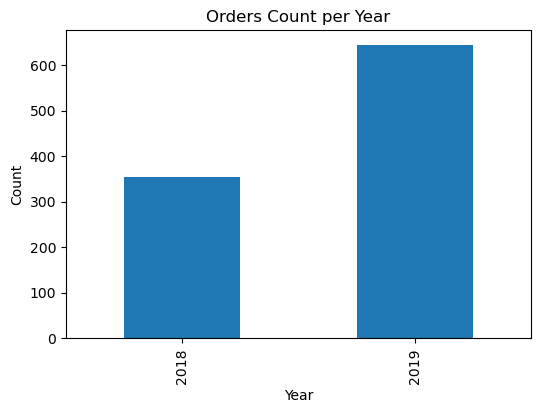

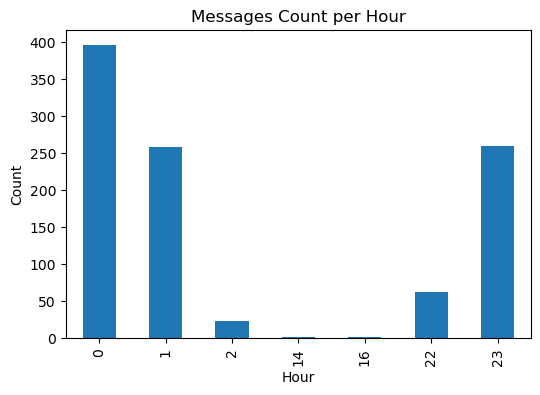

In [10]:
# Orders per year
plt.figure(figsize=(6,4))
orders_df['date_year'].value_counts().sort_index().plot(kind='bar')
plt.title("Orders Count per Year")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

# Messages per hour
plt.figure(figsize=(6,4))
messages_df['hour'].value_counts().sort_index().plot(kind='bar')
plt.title("Messages Count per Hour")
plt.xlabel("Hour")
plt.ylabel("Count")
plt.show()